In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import seaborn as sns

# Monitoria 02/09/2025

# 1. Dieta

Dados de acompanhamento da implementação de uma dieta para aumento de peso

In [ ]:
display(dados.head(4))
display(dados.tail(4))

,Inicio,Fim
0,50.691,53.477
1,48.862,49.322
2,48.950,52.397
3,50.668,53.754


,Inicio,Fim
98543,51.538,50.997
98544,50.633,50.535
98545,49.879,49.770
98546,50.512,50.539


In [ ]:
dados.shape

(98547, 2)

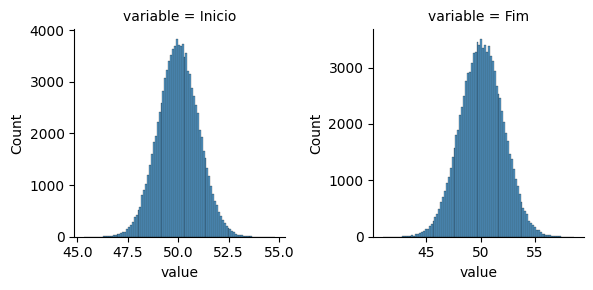

In [ ]:
# Transforma o dataframe para um formato longo
df_melted = pd.melt(dados, var_name='variable', value_name='value')
g = sns.FacetGrid(df_melted, col="variable", col_wrap = 5, sharex=False, sharey=False)
g.map_dataframe(sns.histplot, x = "value", bins = 100)

In [ ]:
summary = df_melted.groupby('variable').describe()

print(summary)

            value                                                             
            count       mean       std     min     25%     50%     75%     max
variable                                                                      
Fim       98547.0  50.110787  2.001369  40.954  48.752  50.110  51.461  58.651
Inicio    98547.0  50.006482  0.996781  45.335  49.337  50.005  50.676  54.811


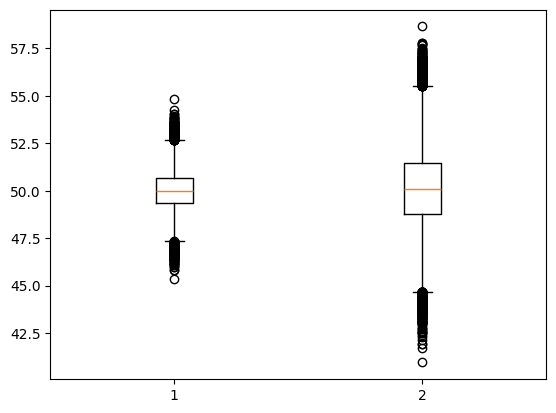

In [ ]:
# Boxplot
plt.boxplot([dados['Inicio'], dados['Fim']])#, whis = 3)
plt.show()

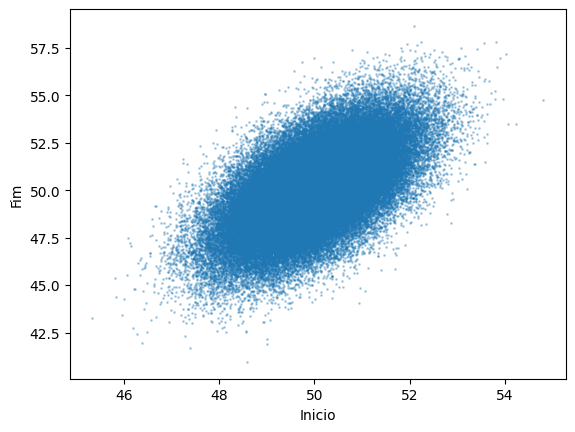

In [ ]:
# grafico de dispersao
plt.scatter(dados['Inicio'], dados['Fim'], alpha=0.3, s=1)
plt.xlabel('Inicio')
plt.ylabel('Fim')
plt.show()

<Axes: ylabel='Count'>

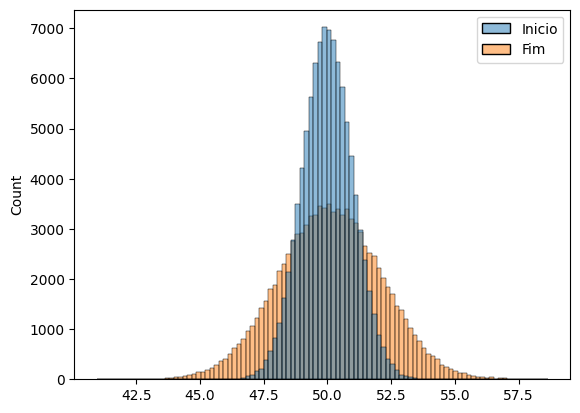

In [ ]:
sns.histplot(dados,  bins = 100)

# O que fazer?

População 1: Peso no início do acompanhamento.

População 2: Peso no final do acompanhamento.

Queremos testar

\begin{cases}
  \mathcal{H}_0: \mu_1 = \mu_2\\
  \mathcal{H}_1: \mu_1 < \mu_2.
\end{cases}

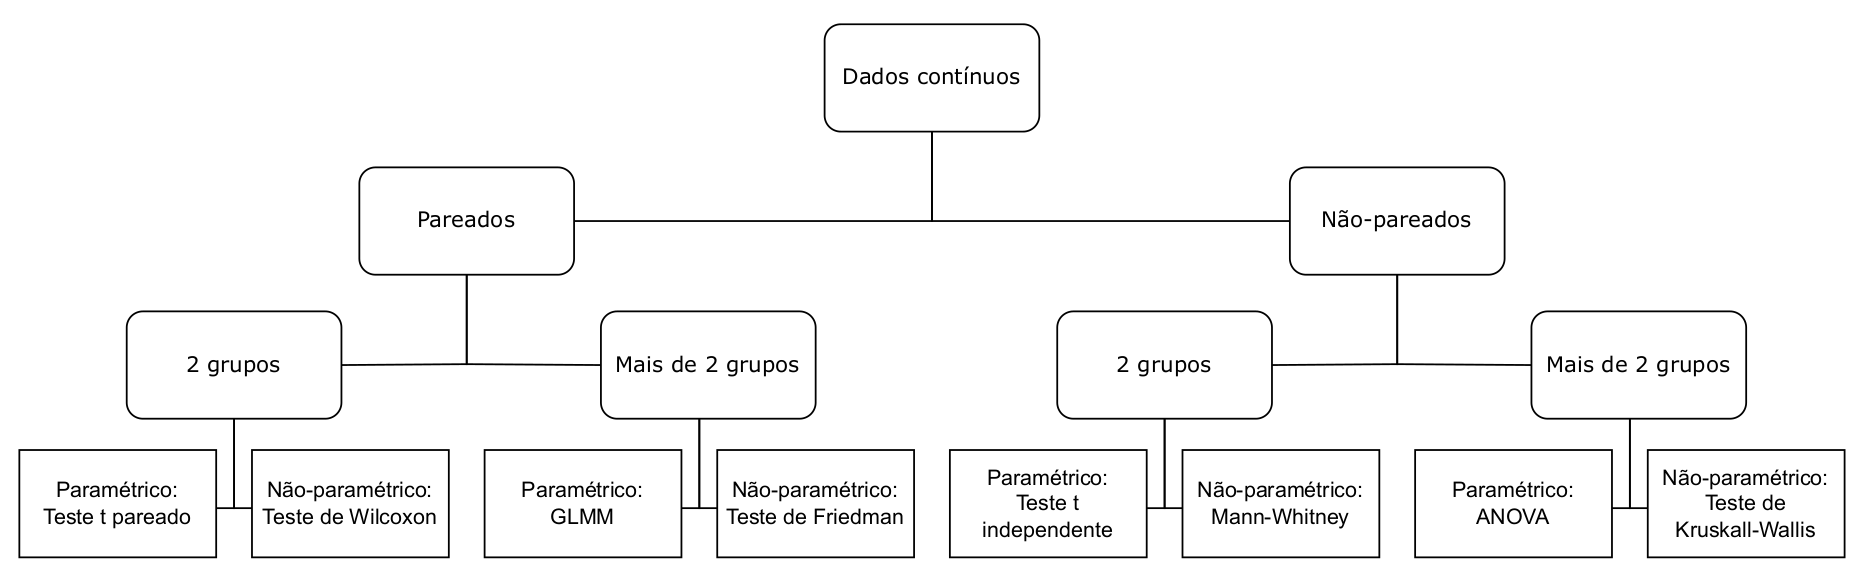

\begin{cases}
  \mathcal{H}_0: \mu_D = 0\\
  \mathcal{H}_1: \mu_D < 0.
\end{cases}

<Axes: ylabel='Count'>

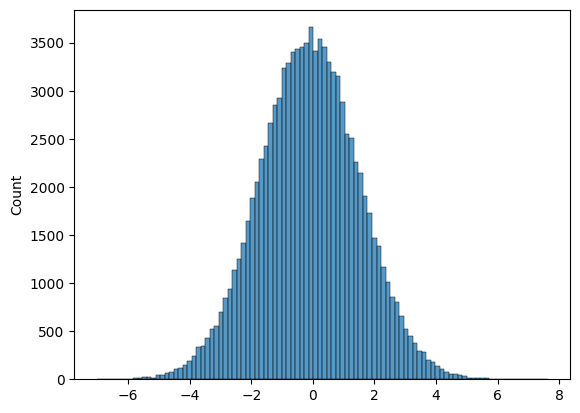

In [ ]:
# Histograma das diferencas
sns.histplot(dados['Inicio']-dados['Fim'], bins = 100)

In [ ]:
diff = dados['Inicio']-dados['Fim']
stat, p = stats.shapiro(diff)
print("Shapiro-Wilk Test: W =", stat, ", p-value =", p)

Shapiro-Wilk Test: W = 0.9999773889636349 , p-value = 0.8565928177919766


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 98547.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
# teste de Kolmogorov–Smirnov
mean_diff = np.mean(diff)
std_diff = np.std(diff, ddof=1)

stat, p = stats.kstest(diff, 'norm', args=(mean_diff, std_diff))
print("Estatística do teste KS: ", stat, ", p-valor: ", p)

Estatística do teste KS:  0.0019366508244687552 , p-valor:  0.8528492010476708


In [ ]:
stat, p = stats.ttest_1samp(diff, 0, alternative = 'less')
print("Estatistica do teste t:", stat, ", p-valor =", p)

Estatistica do teste t: -20.322426534836097 , p-valor = 6.283001065423972e-92


In [ ]:
mean_diff

np.float64(-0.10430465666128852)

Há um ganho de 100 gramas ao final do acompanhamento.

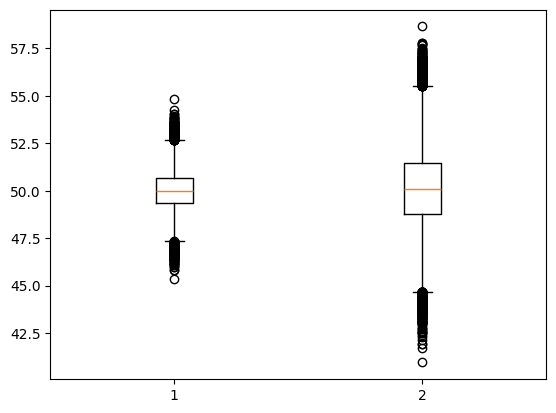

In [ ]:
# Boxplot
plt.boxplot([dados['Inicio'], dados['Fim']])#, whis = 3)
plt.show()

In [ ]:
# gerando os dados

n = 98547

# medias
med_x = 50
med_y = 50.1

# desvios padrao
sd_x = 1
sd_y = 2
S = np.array([sd_x, sd_y])

cor_xy = 0.6

# correlacao e covariancia
corr_matrix = np.array([[1, cor_xy],
                        [cor_xy, 1]])

cov_matrix = np.diag(S) @ corr_matrix @ np.diag(S)

# Gerando dados do estudo
np.random.seed(1)
dados = np.random.multivariate_normal(mean=[med_x, med_y], cov=cov_matrix, size=n)

dados = pd.DataFrame(dados, columns=["Inicio", "Fim"])
dados = dados.round(3)

https://en.wikipedia.org/wiki/Effect_size

# 2. ANOVA com mais fatores

Montgomery, D.C. Design and Analysis of Experiments, Willey, 9th Edition, 2017.

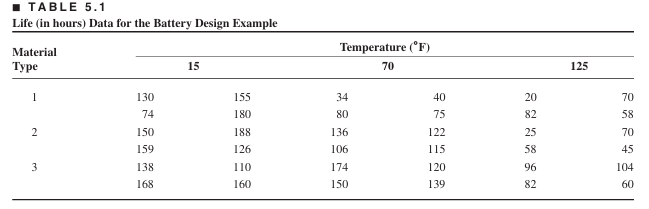

In [47]:
df = pd.DataFrame({
    "Material": [1]*12 + [2]*12 + [3]*12,
    "Temperatura": (
        [15]*4 + [70]*4 + [125]*4 +
        [15]*4 + [70]*4 + [125]*4 +
        [15]*4 + [70]*4 + [125]*4
    ),
    "Tempo": [
        # Material 1
        130, 74, 155, 180,   34, 80, 40, 75,   20, 82, 70, 58,
        # Material 2
        150, 159, 188, 126,  136, 106, 122, 115,  25, 58, 70, 45,
        # Material 3
        138, 168, 110, 160,  174, 150, 120, 139,  96, 82, 104, 60
    ]
})
df["Material"] = df["Material"].astype("category")
df["Temperatura"] = df["Temperatura"].astype("category")

print(df.head(12))
print(df.tail(12))

   Material Temperatura  Tempo
0         1          15    130
1         1          15     74
2         1          15    155
3         1          15    180
4         1          70     34
5         1          70     80
6         1          70     40
7         1          70     75
8         1         125     20
9         1         125     82
10        1         125     70
11        1         125     58
   Material Temperatura  Tempo
24        3          15    138
25        3          15    168
26        3          15    110
27        3          15    160
28        3          70    174
29        3          70    150
30        3          70    120
31        3          70    139
32        3         125     96
33        3         125     82
34        3         125    104
35        3         125     60


<Axes: xlabel='Material', ylabel='Tempo'>

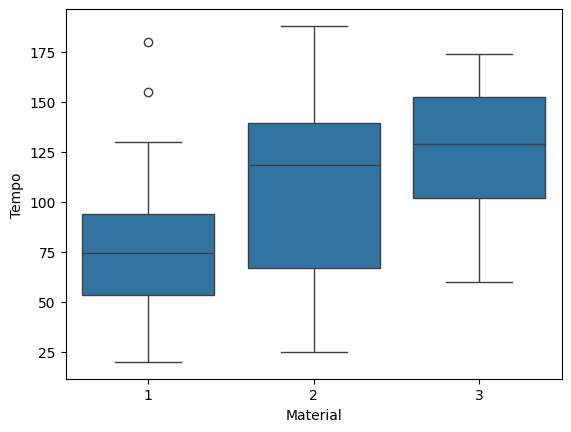

In [48]:
sns.boxplot(x ='Material', y = 'Tempo', data = df)

<Axes: xlabel='Temperatura', ylabel='Tempo'>

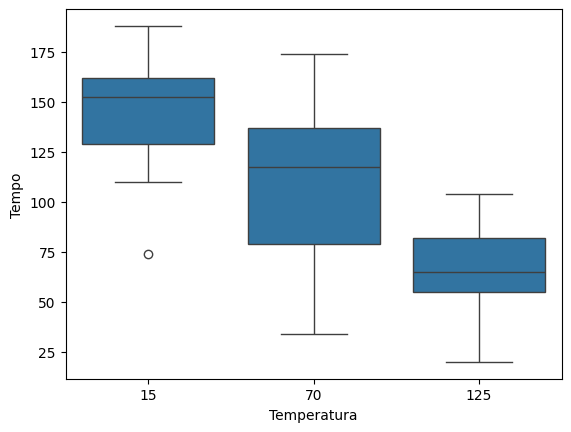

In [49]:
sns.boxplot(x ='Temperatura', y = 'Tempo', data = df)

<Axes: xlabel='Temperatura', ylabel='Tempo'>

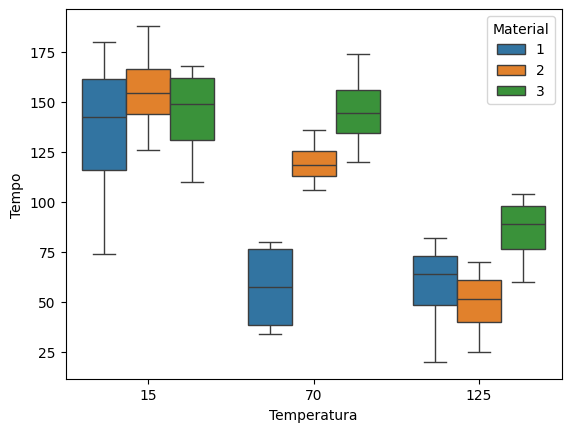

In [57]:
sns.boxplot(x ='Temperatura', y = 'Tempo', data = df, hue = 'Material')

In [60]:
results = {}
for (mat, temp), group in df.groupby(["Material", "Temperatura"]):
    stat, pval = stats.shapiro(group["Tempo"])
    results[(mat, temp)] = (stat, pval)

normality_df = pd.DataFrame(
    [(m, t, s, p) for (m, t), (s, p) in results.items()],
    columns=["Material", "Temperatura", "Shapiro-W", "p-valor"]
)

print(normality_df)

   Material  Temperatura  Shapiro-W   p-valor
0         1           15   0.961033  0.785411
1         1           70   0.838814  0.191968
2         1          125   0.919895  0.536359
3         2           15   0.988172  0.947928
4         2           70   0.986933  0.941278
5         2          125   0.983737  0.923568
6         3           15   0.935797  0.628875
7         3           70   0.994574  0.979563
8         3          125   0.951297  0.724228


/tmp/ipython-input-1621771125.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (mat, temp), group in df.groupby(["Material", "Temperatura"]):


In [52]:
stat, p = stats.levene(
    *[df.loc[(df["Material"]==m) & (df["Temperatura"]==t),"Tempo"]
      for m in df["Material"].cat.categories
      for t in df["Temperatura"].cat.categories]
)

In [53]:
print("Estatística do teste de Levene: ", stat, ", p-valor: ", p)

Estatística do teste de Levene:  0.7995970449966421 , p-valor:  0.6081330500874297


In [55]:
model = ols('Tempo ~ C(Material) * C(Temperatura)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

anova_table

,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,7.911372,1.976083e-03
C(Temperatura),39118.722222,2.0,28.967692,1.908596e-07
C(Material):C(Temperatura),9613.777778,4.0,3.559535,1.861117e-02
Residual,18230.750000,27.0,NaN,NaN


<Axes: xlabel='Temperatura', ylabel='Tempo'>

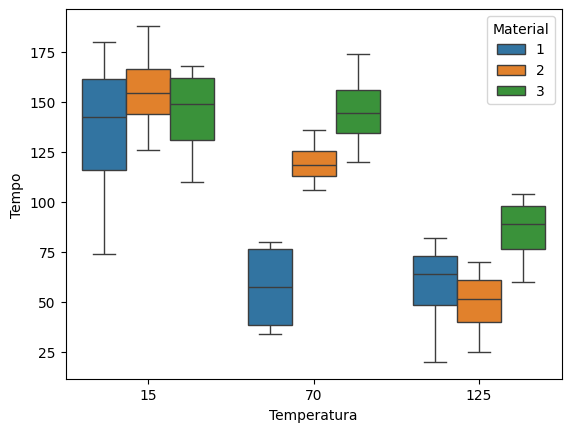

In [58]:
sns.boxplot(x ='Temperatura', y = 'Tempo', data = df, hue = 'Material')